In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("chethuhn/network-intrusion-dataset")

print("Path to dataset files:", path)

100%|██████████| 230M/230M [00:02<00:00, 90.3MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/chethuhn/network-intrusion-dataset/versions/1


This section handles dataset preparation by moving the 'Network Intrusion Dataset' to a specified directory, listing the available files, and merging all CSV files into a single DataFrame. This combined dataset will be used for further preprocessing and model training.

In [ ]:
import shutil
import os

# Path to the extracted dataset
source_path = "/root/.cache/kagglehub/datasets/chethuhn/network-intrusion-dataset/versions/1"
destination_path = "/content/network_intrusion"  # New location in the home directory

# Move the dataset
shutil.move(source_path, destination_path)

# Verify the move
print("Files moved to:", os.path.abspath(destination_path))
print("Files in the new location:", os.listdir(destination_path))


Files moved to: /content/network_intrusion
Files in the new location: ['Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv', 'Tuesday-WorkingHours.pcap_ISCX.csv', 'Wednesday-workingHours.pcap_ISCX.csv', 'Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv', 'Friday-WorkingHours-Morning.pcap_ISCX.csv', 'Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv', 'Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv', 'Monday-WorkingHours.pcap_ISCX.csv']


In [ ]:

files = os.listdir(destination_path)
print("Files in the dataset:", files)

Files in the dataset: ['Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv', 'Tuesday-WorkingHours.pcap_ISCX.csv', 'Wednesday-workingHours.pcap_ISCX.csv', 'Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv', 'Friday-WorkingHours-Morning.pcap_ISCX.csv', 'Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv', 'Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv', 'Monday-WorkingHours.pcap_ISCX.csv']


In [ ]:

import pandas as pd

# Combine all CSV files into one "DataFrame
combined_data = pd.DataFrame()

for file_name in files:
    if file_name.endswith(".csv"):  # Only process CSV files
        file_path = os.path.join(destination_path, file_name)
        print(f"Loading file: {file_name}")
        temp_data = pd.read_csv(file_path)
        combined_data = pd.concat([combined_data, temp_data], ignore_index=True)

print("Combined data shape:", combined_data.shape)
print(combined_data.head())


Loading file: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading file: Tuesday-WorkingHours.pcap_ISCX.csv
Loading file: Wednesday-workingHours.pcap_ISCX.csv
Loading file: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading file: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading file: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading file: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Loading file: Monday-WorkingHours.pcap_ISCX.csv
Combined data shape: (2830743, 79)
    Destination Port   Flow Duration   Total Fwd Packets  \
0                389       113095465                  48   
1                389       113473706                  68   
2                  0       119945515                 150   
3                443        60261928                   9   
4                 53             269                   2   

    Total Backward Packets  Total Length of Fwd Packets  \
0                       24                         9668   
1        

In [ ]:
combined_data[' Label'].unique()

array(['BENIGN', 'Infiltration', 'DDoS', 'Bot',
       'Web Attack � Brute Force', 'Web Attack � XSS',
       'Web Attack � Sql Injection', 'FTP-Patator', 'SSH-Patator',
       'PortScan', 'DoS slowloris', 'DoS Slowhttptest', 'DoS Hulk',
       'DoS GoldenEye', 'Heartbleed'], dtype=object)

This section preprocesses the dataset by handling missing values, encoding categorical columns, and normalizing numerical features. PCA (Principal Component Analysis) is then applied to reduce the dimensionality of the dataset to 64 features. The transformed data is reshaped into an 8×8 matrix with one channel, making it suitable for input into a CNN model.

In [ ]:
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.decomposition import PCA
import numpy as np


# Replace infinite values with NaN and drop them
combined_data.replace([np.inf, -np.inf], np.nan, inplace=True)
combined_data.dropna(inplace=True)

# Encode categorical columns
categorical_cols = combined_data.select_dtypes(include=['object']).columns
encoder = LabelEncoder()
for col in categorical_cols:
    combined_data[col] = encoder.fit_transform(combined_data[col])

y = combined_data[' Label']
combined_data.drop(' Label', axis=1, inplace=True)


# Normalize numeric columns before applying PCA
scaler = MinMaxScaler()
numeric_cols = combined_data.select_dtypes(include=['float64', 'int64']).columns
combined_data[numeric_cols] = scaler.fit_transform(combined_data[numeric_cols])

# Convert the DataFrame to a NumPy array
data_array = combined_data.values

# Apply PCA to reduce features to 64
pca = PCA(n_components=64)
data_array = pca.fit_transform(data_array)

# Reshape the data for CNN input (8x8 matrix with 1 channel)
X = data_array.reshape(-1, 8, 8, 1)

print("X shape after PCA and reshaping:", X.shape)


X shape after PCA and reshaping: (2827876, 8, 8, 1)


In [ ]:
y = y.values
print("y shape:", y.shape)

y shape: (2827876,)


This section defines and compiles a Convolutional Neural Network (CNN) for anomaly detection. The architecture consists of convolutional layers for feature extraction, max-pooling layers for downsampling, and fully connected layers with dropout to prevent overfitting. The model uses global average pooling before classification to improve efficiency. The output layer applies a softmax activation function to classify network traffic into different categories.

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Flatten, Dense, Dropout

# Define CNN model
model = Sequential([
    # Convolutional Layers
    Conv2D(64, kernel_size=(3, 3), activation='relu', input_shape=(8, 8, 1)),
    MaxPooling2D(pool_size=(2, 2)),  # Output: 4x4x64
    Conv2D(128, kernel_size=(3, 3), activation='relu'),  # Output: 2x2x128

    # Global Average Pooling
    GlobalAveragePooling2D(),  # Dynamically reduces spatial dimensions to 1x1

    # Fully Connected Layers
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(len(set(y)), activation='softmax')  # Output layer with class count
])

# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Model summary
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 6, 6, 64)            │             640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 3, 3, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 1, 1, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 256)                 │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 15)                  │           1,935 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 142,351 (556.06 KB)

 Trainable params: 142,351 (556.06 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from sklearn.model_selection import train_test_split

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

# Train the model
history = model.fit(X_train, y_train, epochs=15, batch_size=32, validation_split=0.2)


Training set shape: (2262300, 8, 8, 1)
Testing set shape: (565576, 8, 8, 1)
Epoch 1/15
56558/56558 ━━━━━━━━━━━━━━━━━━━━ 185s 3ms/step - accuracy: 0.9699 - loss: 0.0856 - val_accuracy: 0.9722 - val_loss: 0.6705
Epoch 2/15
56558/56558 ━━━━━━━━━━━━━━━━━━━━ 188s 3ms/step - accuracy: 0.9702 - loss: 0.0866 - val_accuracy: 0.9714 - val_loss: 0.9969
Epoch 3/15
56558/56558 ━━━━━━━━━━━━━━━━━━━━ 187s 3ms/step - accuracy: 0.9702 - loss: 0.0919 - val_accuracy: 0.9726 - val_loss: 1.9662
Epoch 4/15
56558/56558 ━━━━━━━━━━━━━━━━━━━━ 203s 3ms/step - accuracy: 0.9704 - loss: 0.1044 - val_accuracy: 0.9718 - val_loss: 3.8335
Epoch 5/15
56558/56558 ━━━━━━━━━━━━━━━━━━━━ 201s 3ms/step - accuracy: 0.9707 - loss: 0.1292 - val_accuracy: 0.9719 - val_loss: 4.4740
Epoch 6/15
56558/56558 ━━━━━━━━━━━━━━━━━━━━ 203s 4ms/step - accuracy: 0.9706 - loss: 0.1184 - val_accuracy: 0.9718 - val_loss: 6.9470
Epoch 7/15
56558/56558 ━━━━━━━━━━━━━━━━━━━━ 205s 4ms/step - accuracy: 0.9699 - loss: 0.1158 - val_accuracy: 0.9703 - val

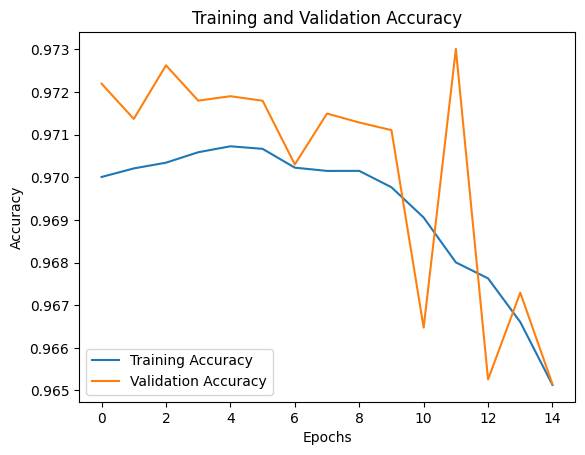

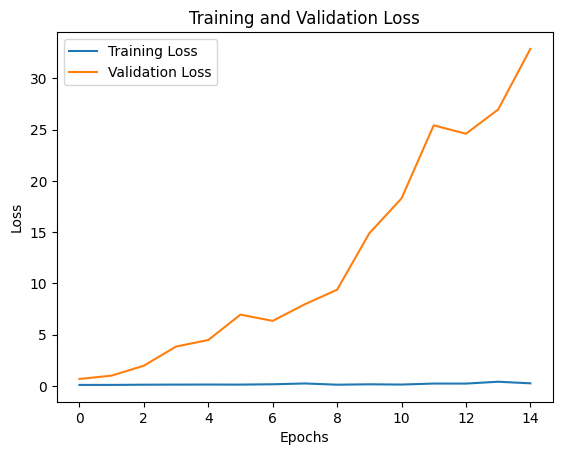

In [ ]:
import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')
plt.show()

# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()


In [ ]:
# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


17675/17675 ━━━━━━━━━━━━━━━━━━━━ 39s 2ms/step - accuracy: 0.9654 - loss: 3.2567
Test Accuracy: 96.53%
Test Loss: 0.6970


17675/17675 ━━━━━━━━━━━━━━━━━━━━ 31s 2ms/step
Classification Report:


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

           0       0.97      0.98      0.98    454187
           1       0.00      0.00      0.00       441
           2       1.00      0.97      0.98     25625
           3       1.00      0.77      0.87      1964
           4       1.00      0.88      0.94     46125
           5       0.97      0.21      0.35      1125
           6       0.23      0.01      0.02      1118
           7       0.00      0.00      0.00      1486
           8       0.00      0.00      0.00         1
           9       0.00      0.00      0.00         7
          10       0.82      1.00      0.90     31877
          11       0.00      0.00      0.00      1216
          12       0.00      0.00      0.00       267
          13       0.00      0.00      0.00         6
          14       0.00      0.00      0.00       131

    accuracy                           0.97    565576
   macro avg       0.40      0.32      0.34    565576
weighted avg       0.96   

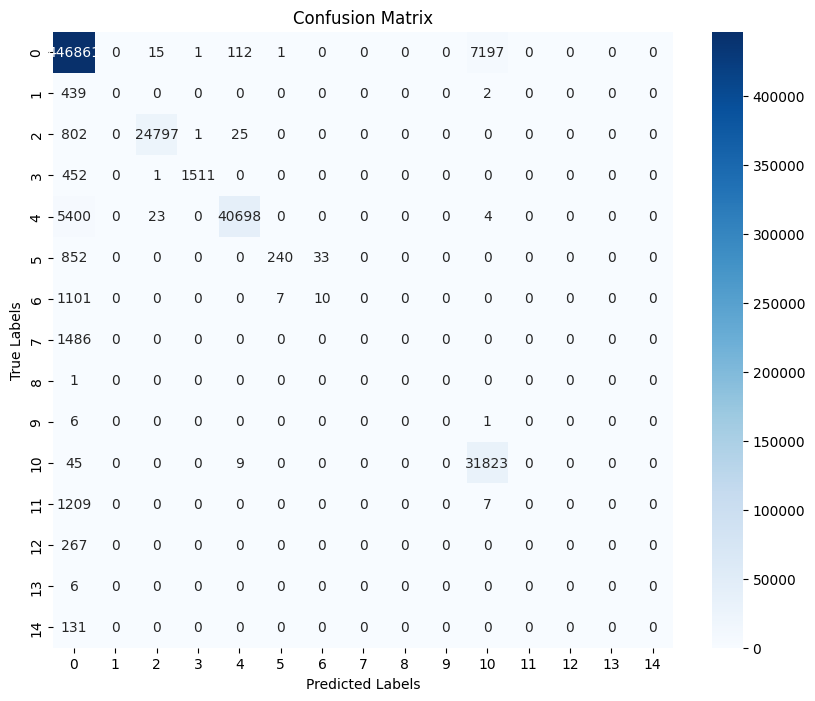

In [ ]:
# Predict on the test set
predictions = model.predict(X_test)

# Convert predictions to class labels
predicted_classes = tf.argmax(predictions, axis=1).numpy()

# Compare predictions with true labels
from sklearn.metrics import classification_report, confusion_matrix

# Print classification report
print("Classification Report:")
print(classification_report(y_test, predicted_classes))

# Display confusion matrix
import seaborn as sns
import numpy as np
cm = confusion_matrix(y_test, predicted_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=set(y), yticklabels=set(y))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
